In [1]:
%matplotlib inline
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd

import astropy.io.fits as pyfits
import astropy.units as u

import sep

import grizli
from grizli import utils
print(f'grizli version: {grizli.__version__}')

import msaexp
import msaexp.spectrum
print(f'msaexp version: {msaexp.__version__}')

BASE_URL = 'https://s3.amazonaws.com/msaexp-nirspec/extractions/'
PATH_TO_FILE = BASE_URL + '{root}/{file}'

grizli version: 1.14.2
msaexp version: 0.9.17


In [3]:
data = pyfits.open('/mnt/c/Users/nicol/Desktop/Proyecto_Astronomico/Astronomical_Investigation_Project/data/aurora-gdn02-v4_g140m-f100lp_1914_931951.spec.fits')

data.info()

Filename: /mnt/c/Users/nicol/Desktop/Proyecto_Astronomico/Astronomical_Investigation_Project/data/aurora-gdn02-v4_g140m-f100lp_1914_931951.spec.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1  SPEC1D        1 BinTableHDU    381   4667R x 9C   [D, D, D, D, D, D, D, D, D]   
  2  SCI           1 ImageHDU       358   (4667, 31)   float64   
  3  WHT           1 ImageHDU       358   (4667, 31)   float64   
  4  PROFILE       1 ImageHDU       358   (4667, 31)   float64   
  5  PROF1D        1 BinTableHDU     25   31R x 3C   [D, D, D]   
  6  BACKGROUND    1 ImageHDU       358   (4667, 31)   float64   
  7  SLITS         1 BinTableHDU    107   12R x 49C   [67A, K, K, D, D, D, D, D, K, 11A, D, D, D, D, 3A, K, K, D, D, K, K, K, K, K, K, K, 4A, 5A, 6A, 25A, K, K, D, K, K, K, 7A, D, D, D, D, 17A, K, K, 4A, K, K, D, D]   


In [4]:
data[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   72 / length of dimension 1                          
NAXIS2  =                 4667 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    9 / number of table fields                         
VERSION = '0.9.5.dev2+g80b81b4' / msaexp software version                       
TOMUJY  =                  1.0 / Conversion from pixel values to microJansky    
PROFCEN = 0.000999999999997795 / PRF profile center                             
PROFSIG =  0.46592551056485865 / PRF profile sigma                              
PROFSTRT=                   

In [ ]:
# Upper limits
# Hb -> 1015.71951937185
# OIII -> 2609.8848694425433

2609.8848694425433


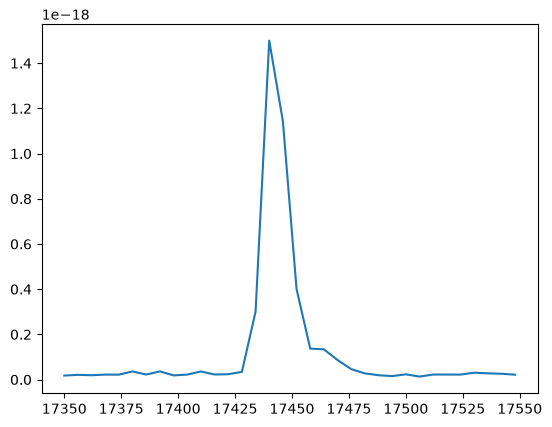

In [36]:
flux = data[1].data['flux']
wave = data[1].data['wave'] * 1e4

# plt.plot(wave, flux)
# plt.ylim(-5, 30)
# plt.xlim(17350, 17550)

mask = ((wave > 17350) & (wave < 17550))

wave = wave[mask]
flux = flux[mask]

flux = flux / wave**2 * 3*1e18 * 1e-29

plt.plot(wave, flux)

from scipy.integrate import trapezoid

print(trapezoid(flux, wave) * 1e20)

